# Homework 12 — Part 2: Knowledge Distillation (BERT → DistilBERT on AG News)

**Student parameters (standing Step 0 rule):** `SID4 = 2122`, `SEED = 2122`, `HP_ID = 2122 mod 6 = 4`
(HW12 defines no HP_ID-specific setting; as the PDF says, HP_ID does **not** add another temperature.)

| Item | Value |
|---|---|
| Dataset | AG News (`fancyzhx/ag_news`): 120,000 train / 7,600 test, 4 classes |
| Teacher | BERT-base classifier fine-tuned on AG News (see the note in §2) |
| Student | `distilbert-base-uncased`, re-initialised from the same pretrained checkpoint for every run |
| Loss | `loss = α·CE(student, y) + (1−α)·KLD(teacher_T ‖ student_T)` |
| Sweeps | T ∈ {1, 2, 5, 10} at α = 0.5; then α ∈ {0.25, 0.5, 0.75} at the best T |
| Hardware | the same local GPU for every run (printed below) |

Model selection (best T, best α) uses a **held-out validation split** carved from the training set, so the
test set is used only for reporting.

In [1]:
import os, sys, time, json, math, random, shutil, platform, datetime
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
import transformers, datasets
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SID4 = 2122
SEED = SID4
HP_ID = SID4 % 6
QUICK = os.environ.get("HW12_QUICK", "0") == "1"      # smoke-test mode (tiny subsets); final run uses 0

ROOT = os.path.abspath(".")
SUF = "_quick" if QUICK else ""
RES, FIG, LOGS, CKPT = (os.path.join(ROOT, p + SUF) for p in ("results/part2", "results/figures", "logs", "checkpoints"))
for p in (RES, FIG, LOGS, CKPT): os.makedirs(p, exist_ok=True)
TEACHER_DIR = os.path.join(ROOT, "teacher_model" + SUF)
STUDENT_CKPT = "distilbert-base-uncased"
TEACHER_BASE = "bert-base-uncased"   # only used if ./teacher_model is absent
LOGFILE = os.path.join(LOGS, "part2_distillation.log")

def log(msg):
    line = f"[{datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] {msg}"
    print(line, flush=True)
    with open(LOGFILE, "a", encoding="utf-8") as f: f.write(line + "\n")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = torch.device("cuda")
log(f"===== Part 2 run started (QUICK={QUICK}) =====")
log(f"SID4={SID4} SEED={SEED} HP_ID={HP_ID}")
log(f"GPU: {torch.cuda.get_device_name(0)} | torch {torch.__version__} | CUDA {torch.version.cuda} | "
    f"transformers {transformers.__version__} | datasets {datasets.__version__} | python {platform.python_version()} | {platform.platform()}")

/home/sam02/hw12-gptq/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-11-24 11:08:58] ===== Part 2 run started (QUICK=False) =====


[2026-11-24 11:08:58] SID4=2122 SEED=2122 HP_ID=4


[2026-11-24 11:08:58] GPU: NVIDIA GeForce RTX 3060 Laptop GPU | torch 2.15.0+cu132 | CUDA 13.2 | transformers 5.24.1 | datasets 5.2.0 | python 3.12.3 | Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39


## 1. Data: AG News, fixed train/validation split
A stratified 5 % validation split (6,000 samples, `random_state = SEED`) is held out from the 120k training set for model
selection. Teacher logits are still extracted for **all 120,000** training samples.

In [2]:
from sklearn.model_selection import train_test_split
ds = load_dataset("fancyzhx/ag_news")
CLASSES = ds["train"].features["label"].names
train_text, train_y = list(ds["train"]["text"]), np.array(ds["train"]["label"])
test_text,  test_y  = list(ds["test"]["text"]),  np.array(ds["test"]["label"])
all_idx = np.arange(len(train_text))
tr_idx, va_idx = train_test_split(all_idx, test_size=0.05, random_state=SEED, stratify=train_y)
if QUICK:
    tr_idx, va_idx = tr_idx[:3000], va_idx[:500]
    test_text, test_y = test_text[:800], test_y[:800]
log(f"classes={CLASSES} | train(all)={len(train_text)} train(fit)={len(tr_idx)} val={len(va_idx)} test={len(test_text)}")
print(pd.Series(train_y[tr_idx]).map(dict(enumerate(CLASSES))).value_counts().rename("train count"))

[2026-11-24 11:09:04] classes=['World', 'Sports', 'Business', 'Sci/Tech'] | train(all)=120000 train(fit)=114000 val=6000 test=7600


Sports      28500
Sci/Tech    28500
World       28500
Business    28500
Name: train count, dtype: int64


In [3]:
MAX_LEN = 128
tok = AutoTokenizer.from_pretrained(STUDENT_CKPT)   # bert-base-uncased and distilbert-base-uncased share the same WordPiece vocab
def encode(texts):
    return tok(texts, truncation=True, max_length=MAX_LEN)["input_ids"]
t0 = time.time()
train_ids = encode(train_text)          # all 120k (needed for teacher logits)
test_ids  = encode(test_text)
lens = np.array([len(x) for x in train_ids])
log(f"tokenised in {time.time()-t0:.1f}s | train tokens/sample mean={lens.mean():.1f} p95={np.percentile(lens,95):.0f} max={lens.max()} | truncated(>={MAX_LEN})={(lens>=MAX_LEN).mean()*100:.2f}%")

def collate(ids_list, pad_id=tok.pad_token_id):
    L = max(len(x) for x in ids_list)
    ids = torch.full((len(ids_list), L), pad_id, dtype=torch.long)
    att = torch.zeros((len(ids_list), L), dtype=torch.long)
    for i, x in enumerate(ids_list):
        ids[i, :len(x)] = torch.tensor(x); att[i, :len(x)] = 1
    return ids, att

def batches(index, bs, shuffle=False, gen=None):
    index = np.asarray(index)
    order = index[gen.permutation(len(index))] if shuffle else index
    for i in range(0, len(order), bs):
        yield order[i:i+bs]

[2026-11-24 11:09:14] tokenised in 8.4s | train tokens/sample mean=52.8 p95=82 max=128 | truncated(>=128)=0.80%


## 2. Teacher model
The PDF provides a fine-tuned BERT teacher in a Google Drive `teacher_model` folder. That link is restricted to SJSU
Google accounts and returned **HTTP 401** from this machine, so a stand-in teacher was trained with the same recipe the folder describes
(a BERT-base model fine-tuned on AG News). **If `./teacher_model` already contains a model, it is loaded as-is and no training
happens**, so the instructor's teacher can be dropped in and the notebook re-run unchanged.

Stand-in recipe: `bert-base-uncased`, 1 epoch over the 114k fit split, batch 32, AdamW lr 2e-5, wd 0.01, 6 % linear warm-up,
fp16 autocast, max length 128, seed = SEED.

In [4]:
@torch.no_grad()
def predict_logits(model, ids_list, index=None, bs=128, amp=True):
    model.eval()
    index = np.arange(len(ids_list)) if index is None else np.asarray(index)
    out = np.zeros((len(index), model.config.num_labels), dtype=np.float32)
    pos = 0
    for b in batches(index, bs):
        ids, att = collate([ids_list[i] for i in b])
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            lg = model(input_ids=ids.to(device), attention_mask=att.to(device)).logits
        out[pos:pos+len(b)] = lg.float().cpu().numpy(); pos += len(b)
    return out

def make_sched(opt, total, warm_frac=0.06):
    warm = max(1, int(total * warm_frac))
    return torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s+1)/warm if s < warm else max(0.0, (total-s)/max(1, total-warm)))

def has_weights(d):
    return os.path.isdir(d) and any(f.endswith((".safetensors", ".bin")) for f in os.listdir(d))

if has_weights(TEACHER_DIR):
    TEACHER_SOURCE = "provided ./teacher_model folder"
    log(f"Loading teacher from {TEACHER_DIR}")
else:
    TEACHER_SOURCE = f"stand-in: {TEACHER_BASE} fine-tuned here (instructor Drive folder was access-restricted)"
    log(f"No teacher in {TEACHER_DIR} -> fine-tuning stand-in teacher from {TEACHER_BASE}")
    set_seed(SEED)
    tmodel = AutoModelForSequenceClassification.from_pretrained(
        TEACHER_BASE, num_labels=4, id2label=dict(enumerate(CLASSES)), label2id={c: i for i, c in enumerate(CLASSES)}).to(device)
    BS, LR, EPOCHS = 32, 2e-5, 1
    steps = EPOCHS * math.ceil(len(tr_idx) / BS)
    opt = torch.optim.AdamW(tmodel.parameters(), lr=LR, weight_decay=0.01)
    sch = make_sched(opt, steps); scaler = torch.amp.GradScaler()
    gen = np.random.default_rng(SEED); step = 0; t0 = time.time(); run = []
    tmodel.train()
    for ep in range(EPOCHS):
        for b in batches(tr_idx, BS, shuffle=True, gen=gen):
            ids, att = collate([train_ids[i] for i in b]); y = torch.tensor(train_y[b], device=device)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = F.cross_entropy(tmodel(input_ids=ids.to(device), attention_mask=att.to(device)).logits.float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(tmodel.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step()
            step += 1; run.append(loss.item())
            if step % 500 == 0 or step == steps:
                log(f"[teacher] step {step}/{steps} loss(avg last 500)={np.mean(run[-500:]):.4f} lr={sch.get_last_lr()[0]:.2e} elapsed={time.time()-t0:.0f}s")
    va_acc = (predict_logits(tmodel, train_ids, va_idx).argmax(1) == train_y[va_idx]).mean()
    log(f"[teacher] finished in {time.time()-t0:.0f}s | val acc={va_acc:.4f}")
    tmodel.save_pretrained(TEACHER_DIR); tok.save_pretrained(TEACHER_DIR)
    with open(os.path.join(TEACHER_DIR, "TEACHER_README.txt"), "w") as f:
        f.write(f"Stand-in teacher: {TEACHER_BASE} fine-tuned 1 epoch on AG News fit split (seed {SEED}).\n"
                f"Validation accuracy {va_acc:.4f}. Generated by HW12_Part2_Distillation.ipynb.\n")
    del tmodel, opt; torch.cuda.empty_cache()

teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(device).eval()
log(f"Teacher source: {TEACHER_SOURCE} | arch={teacher.config.architectures} | params={sum(p.numel() for p in teacher.parameters())/1e6:.1f}M")

[2026-11-24 11:09:14] No teacher in /mnt/c/Users/samru/Study/Study_Abroad/Universities/SJSU/Semester3/Data_266_Generative_AI/Assignments/Assignment12/teacher_model -> fine-tuning stand-in teacher from bert-base-uncased


W1124 11:09:17.939000 371 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1124 11:09:18.020000 371 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  46%|████▌     | 92/199 [00:00<00:00, 893.31it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1214.06it/s]

... (13 outputs left out)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  40%|████      | 81/201 [00:00<00:00, 793.95it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1051.29it/s]

[2026-11-24 11:19:49] Teacher source: stand-in: bert-base-uncased fine-tuned here (instructor Drive folder was access-restricted) | arch=['BertForSequenceClassification'] | params=109.5M


## 3. Extract teacher logits for all AG News training samples

In [5]:
t0 = time.time()
teacher_logits_all = predict_logits(teacher, train_ids, np.arange(len(train_ids)), bs=256)
log(f"Teacher logits extracted for {len(teacher_logits_all)} training samples in {time.time()-t0:.1f}s; shape={teacher_logits_all.shape}")
np.save(os.path.join(RES, "teacher_train_logits.npy"), teacher_logits_all)
t_pred = teacher_logits_all.argmax(1)
log(f"Teacher accuracy on fit split={(t_pred[tr_idx]==train_y[tr_idx]).mean():.4f} | on held-out val={(t_pred[va_idx]==train_y[va_idx]).mean():.4f}")
for T in (1, 2, 5, 10):
    p = torch.softmax(torch.tensor(teacher_logits_all[tr_idx]) / T, -1)
    log(f"  teacher soft targets at T={T:>2}: mean max-prob={p.max(1).values.mean():.3f}  mean entropy={-(p*p.clamp_min(1e-12).log()).sum(1).mean():.3f} nats")

[2026-11-24 11:22:46] Teacher logits extracted for 120000 training samples in 176.9s; shape=(120000, 4)


[2026-11-24 11:22:46] Teacher accuracy on fit split=0.9576 | on held-out val=0.9442


[2026-11-24 11:22:46]   teacher soft targets at T= 1: mean max-prob=0.956  mean entropy=0.137 nats


[2026-11-24 11:22:46]   teacher soft targets at T= 2: mean max-prob=0.839  mean entropy=0.533 nats


[2026-11-24 11:22:46]   teacher soft targets at T= 5: mean max-prob=0.530  mean entropy=1.181 nats


[2026-11-24 11:22:47]   teacher soft targets at T=10: mean max-prob=0.383  mean entropy=1.336 nats


## 4. Distillation loss and training loop
$$\mathcal{L} = \alpha\,\mathrm{CE}\big(z_s, y\big) + (1-\alpha)\,T^2\,\mathrm{KL}\big(\mathrm{softmax}(z_t/T)\,\|\,\mathrm{softmax}(z_s/T)\big)$$

The KL term is multiplied by $T^2$ (Hinton et al., 2015). Without it, the soft-target gradients shrink as $1/T^2$, so the
temperature sweep would really be a sweep over the effective weight of the KD term. With the factor, α keeps the same meaning
at every T. Every run uses the **same fixed settings**: student re-loaded from `distilbert-base-uncased`, `set_seed(SEED)` before
model creation (so the classifier head starts the same), the same data order (`default_rng(SEED)`), 1 epoch, batch 32,
AdamW lr 5e-5, wd 0.01, 6 % warm-up then linear decay, grad-clip 1.0, fp16 autocast, max length 128.

In [6]:
def kd_loss(s_logits, t_logits, labels, T, alpha):
    s_logits, t_logits = s_logits.float(), t_logits.float()
    ce = F.cross_entropy(s_logits, labels)
    kl = F.kl_div(F.log_softmax(s_logits / T, -1), F.log_softmax(t_logits / T, -1),
                  reduction="batchmean", log_target=True) * (T * T)
    return alpha * ce + (1 - alpha) * kl, ce, kl

TRAIN_CFG = dict(epochs=1, bs=32, lr=5e-5, wd=0.01, warmup=0.06, max_len=MAX_LEN, clip=1.0, amp="fp16", seed=SEED)
LOG_EVERY = 50 if QUICK else 500
t_logits_gpu = torch.tensor(teacher_logits_all, device=device)

def train_student(T, alpha, tag):
    cfg = dict(TRAIN_CFG, T=T, alpha=alpha)
    out_json, out_dir = os.path.join(RES, "runs", f"{tag}.json"), os.path.join(CKPT, tag)
    if os.path.exists(out_json) and has_weights(out_dir) and not QUICK:
        log(f"[{tag}] cached result found -> loading"); return json.load(open(out_json))
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_CKPT, num_labels=4, id2label=dict(enumerate(CLASSES)), label2id={c: i for i, c in enumerate(CLASSES)}).to(device)
    steps = cfg["epochs"] * math.ceil(len(tr_idx) / cfg["bs"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sch = make_sched(opt, steps, cfg["warmup"]); scaler = torch.amp.GradScaler()
    gen = np.random.default_rng(SEED); hist = []; buf = []; step = 0; t0 = time.time()
    log(f"[{tag}] start: T={T} alpha={alpha} steps={steps} cfg={TRAIN_CFG}")
    model.train()
    for ep in range(cfg["epochs"]):
        for b in batches(tr_idx, cfg["bs"], shuffle=True, gen=gen):
            ids, att = collate([train_ids[i] for i in b])
            y = torch.tensor(train_y[b], device=device); bt = torch.as_tensor(b, device=device)
            with torch.autocast("cuda", dtype=torch.float16):
                s = model(input_ids=ids.to(device), attention_mask=att.to(device)).logits
            loss, ce, kl = kd_loss(s, t_logits_gpu[bt], y, T, alpha)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"]); scaler.step(opt); scaler.update(); sch.step()
            step += 1; buf.append((loss.item(), ce.item(), kl.item()))
            if step % LOG_EVERY == 0 or step == steps:
                l, c, k = np.mean(buf, 0); buf = []
                hist.append(dict(step=step, loss=l, ce=c, kl=k, lr=sch.get_last_lr()[0]))
                log(f"[{tag}] step {step:>5}/{steps} loss={l:.4f} CE={c:.4f} KL*T^2={k:.4f} lr={sch.get_last_lr()[0]:.2e} {time.time()-t0:.0f}s")
    train_time = time.time() - t0
    va_logits = predict_logits(model, train_ids, va_idx)
    te_logits = predict_logits(model, test_ids)
    va_acc = float((va_logits.argmax(1) == train_y[va_idx]).mean()); te_acc = float((te_logits.argmax(1) == test_y).mean())
    va_ce = float(F.cross_entropy(torch.tensor(va_logits), torch.tensor(train_y[va_idx])).item())
    agree = float((te_logits.argmax(1) == TEACHER_TEST_PRED).mean())
    log(f"[{tag}] done in {train_time:.0f}s | val acc={va_acc:.4f} val CE={va_ce:.4f} | test acc={te_acc:.4f} | test agreement w/ teacher={agree:.4f}")
    res = dict(tag=tag, T=T, alpha=alpha, val_acc=va_acc, val_ce=va_ce, test_acc=te_acc, teacher_agreement=agree,
               train_time_s=train_time, history=hist, cfg=cfg)
    os.makedirs(os.path.dirname(out_json), exist_ok=True); json.dump(res, open(out_json, "w"), indent=1)
    model.save_pretrained(out_dir); tok.save_pretrained(out_dir)
    del model, opt; torch.cuda.empty_cache()
    return res

TEACHER_TEST_LOGITS = predict_logits(teacher, test_ids)
TEACHER_TEST_PRED = TEACHER_TEST_LOGITS.argmax(1)
log(f"Teacher test accuracy = {(TEACHER_TEST_PRED == test_y).mean():.4f}")
teacher = None; torch.cuda.empty_cache()   # free the teacher while students train (logits are cached)

[2026-11-24 11:22:57] Teacher test accuracy = 0.9420


## 5. Temperature sweep: T = 1, 2, 5, 10 (α = 0.5)
A sample of the training log is printed below; the full log is in `logs/part2_distillation.log`.

In [7]:
TEMPS = [1, 2, 5, 10]
t_runs = [train_student(T, 0.5, f"T{T}_a0.5") for T in TEMPS]
t_df = pd.DataFrame([{k: r[k] for k in ("T", "alpha", "val_acc", "val_ce", "test_acc", "teacher_agreement", "train_time_s")} for r in t_runs])
BEST_T = int(t_df.sort_values(["val_acc", "val_ce"], ascending=[False, True]).iloc[0]["T"])
t_df.to_csv(os.path.join(RES, "temperature_sweep.csv"), index=False)
log(f"Temperature sweep:\n{t_df.to_string(index=False)}\nBEST_T (highest val acc, ties -> lower val CE) = {BEST_T}")
display(t_df.style.format({"val_acc": "{:.4f}", "val_ce": "{:.4f}", "test_acc": "{:.4f}", "teacher_agreement": "{:.4f}", "train_time_s": "{:.0f}"}))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1166.96it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[2026-11-24 11:22:58] [T1_a0.5] start: T=1 alpha=0.5 steps=3563 cfg={'epochs': 1, 'bs': 32, 'lr': 5e-05, 'wd': 0.01, 'warmup': 0.06, 'max_len': 128, 'clip': 1.0, 'amp': 'fp16', 'seed': 2122}


[2026-11-24 11:23:44] [T1_a0.5] step   500/3563 loss=0.3585 CE=0.4303 KL*T^2=0.2866 lr=4.57e-05 46s


[2026-11-24 11:24:30] [T1_a0.5] step  1000/3563 loss=0.1662 CE=0.2403 KL*T^2=0.0922 lr=3.83e-05 92s


... (56 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.16s/it]

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.16s/it]

[2026-11-24 11:45:44] Temperature sweep:
 T  alpha  val_acc   val_ce  test_acc  teacher_agreement  train_time_s
 1    0.5 0.944000 0.156998  0.944605           0.983289    326.963524
 2    0.5 0.943500 0.159394  0.943816           0.982763    327.520231
 5    0.5 0.943333 0.159768  0.943421           0.982500    329.179491
10    0.5 0.941667 0.159606  0.943553           0.983947    329.838367
BEST_T (highest val acc, ties -> lower val CE) = 1


,T,alpha,val_acc,val_ce,test_acc,teacher_agreement,train_time_s
0,1,0.500000,0.9440,0.1570,0.9446,0.9833,327
1,2,0.500000,0.9435,0.1594,0.9438,0.9828,328
2,5,0.500000,0.9433,0.1598,0.9434,0.9825,329
3,10,0.500000,0.9417,0.1596,0.9436,0.9839,330


## 6. Loss-weighting sweep at the best T: α = 0.25, 0.5, 0.75
Three fresh students, all other settings unchanged.

In [8]:
ALPHAS = [0.25, 0.5, 0.75]
a_runs = [train_student(BEST_T, a, f"T{BEST_T}_a{a}_alphasweep") for a in ALPHAS]
a_df = pd.DataFrame([{k: r[k] for k in ("T", "alpha", "val_acc", "val_ce", "test_acc", "teacher_agreement", "train_time_s")} for r in a_runs])
a_df.to_csv(os.path.join(RES, "alpha_sweep.csv"), index=False)
best_run = max(t_runs + a_runs, key=lambda r: (r["val_acc"], -r["val_ce"]))
BEST_TAG, BEST_ALPHA = best_run["tag"], best_run["alpha"]
log(f"Alpha sweep at T={BEST_T}:\n{a_df.to_string(index=False)}\nBest distilled student overall (by val acc): {BEST_TAG} (T={best_run['T']}, alpha={BEST_ALPHA})")
display(a_df.style.format({"val_acc": "{:.4f}", "val_ce": "{:.4f}", "test_acc": "{:.4f}", "teacher_agreement": "{:.4f}", "train_time_s": "{:.0f}"}))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1934.42it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[2026-11-24 11:45:45] [T1_a0.25_alphasweep] start: T=1 alpha=0.25 steps=3563 cfg={'epochs': 1, 'bs': 32, 'lr': 5e-05, 'wd': 0.01, 'warmup': 0.06, 'max_len': 128, 'clip': 1.0, 'amp': 'fp16', 'seed': 2122}


[2026-11-24 11:46:31] [T1_a0.25_alphasweep] step   500/3563 loss=0.3206 CE=0.4280 KL*T^2=0.2848 lr=4.57e-05 46s


[2026-11-24 11:47:17] [T1_a0.25_alphasweep] step  1000/3563 loss=0.1241 CE=0.2365 KL*T^2=0.0866 lr=3.83e-05 92s


... (40 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.02s/it]

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.02s/it]

[2026-11-24 12:02:43] Alpha sweep at T=1:
 T  alpha  val_acc   val_ce  test_acc  teacher_agreement  train_time_s
 1   0.25 0.942333 0.161043  0.943553           0.983947    327.058505
 1   0.50 0.944000 0.156998  0.944605           0.983289    327.168961
 1   0.75 0.944833 0.157047  0.943158           0.978553    326.662389
Best distilled student overall (by val acc): T1_a0.75_alphasweep (T=1, alpha=0.75)


,T,alpha,val_acc,val_ce,test_acc,teacher_agreement,train_time_s
0,1,0.250000,0.9423,0.1610,0.9436,0.9839,327
1,1,0.500000,0.9440,0.1570,0.9446,0.9833,327
2,1,0.750000,0.9448,0.1570,0.9432,0.9786,327


### Loss trends
Each point is the mean over the preceding logging window. The KL term is shown already multiplied by $T^2$.

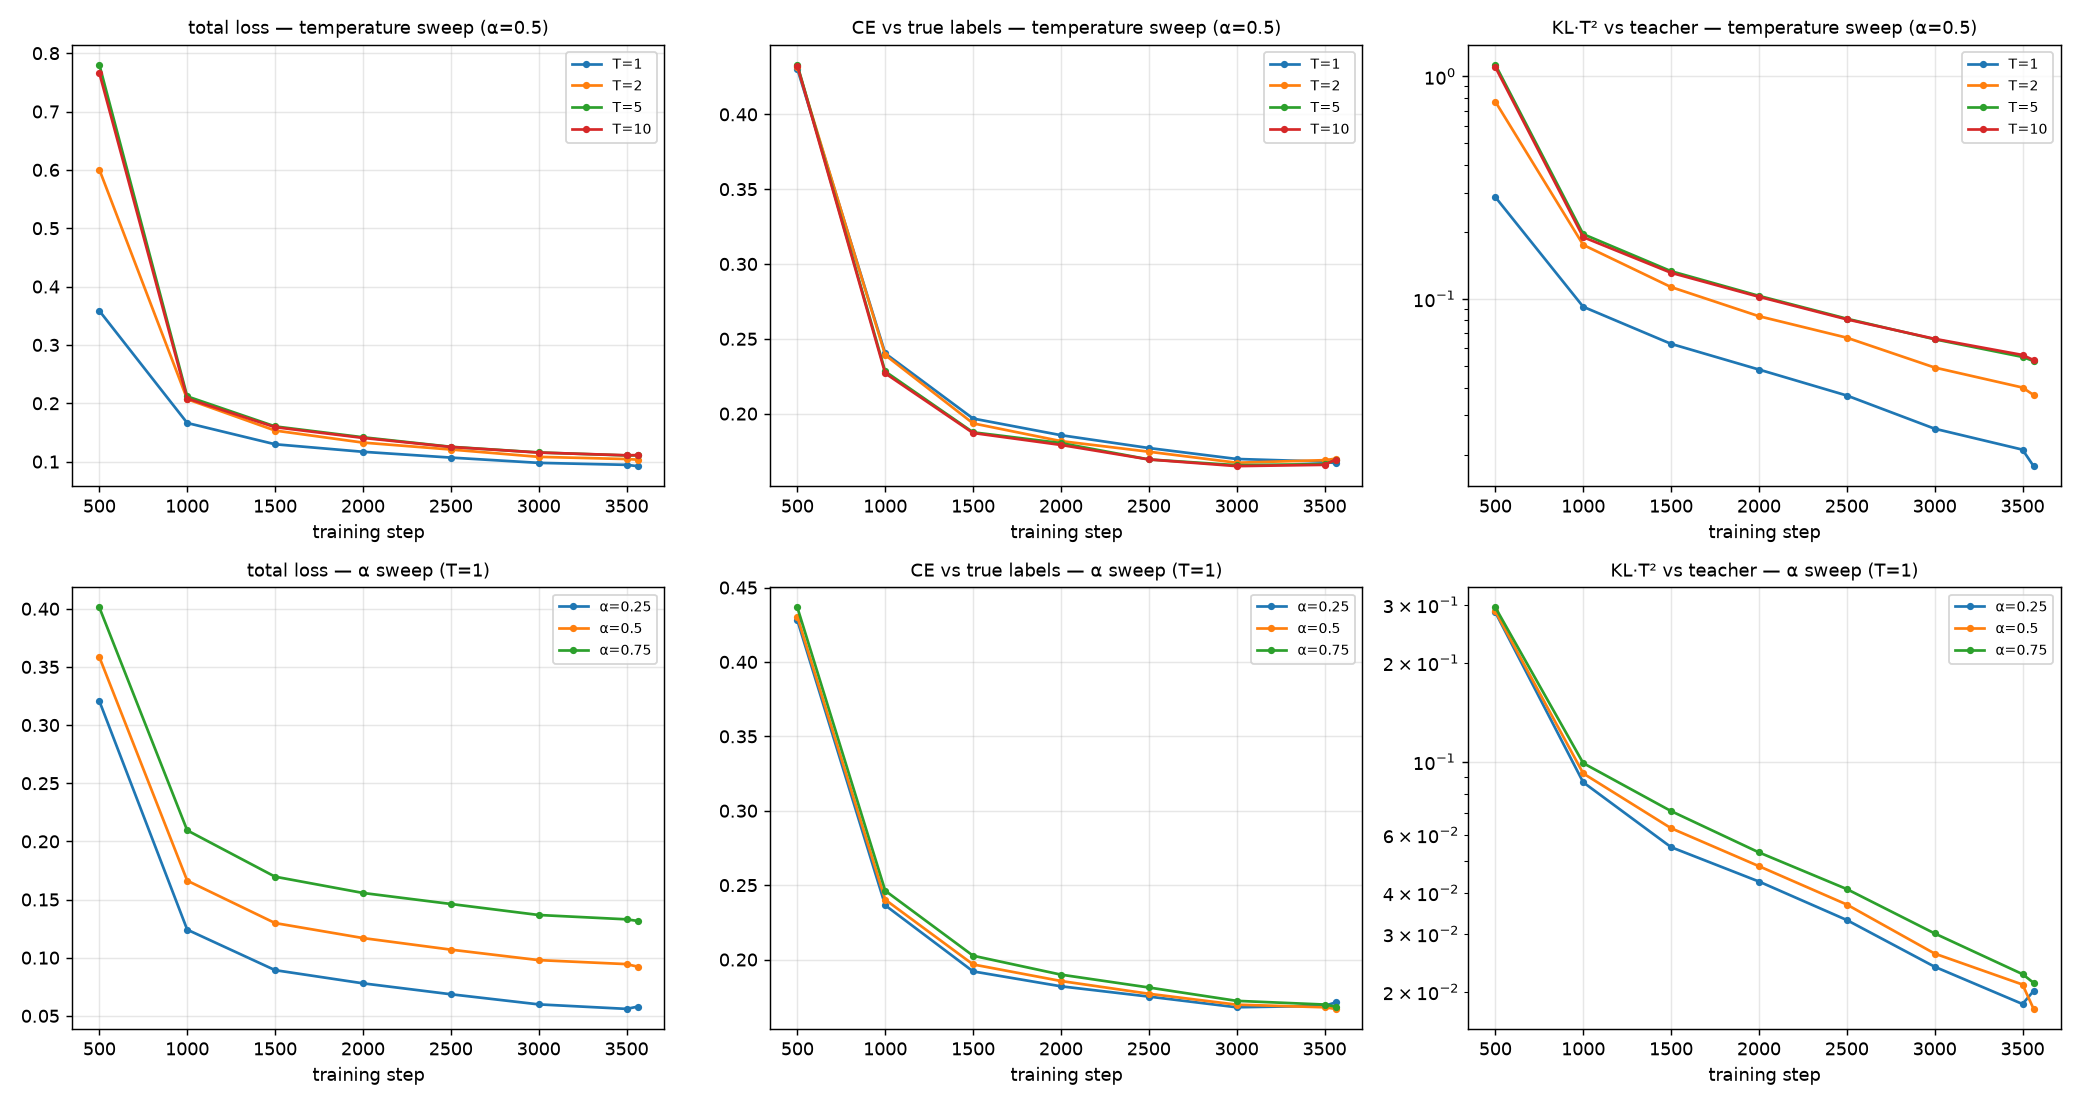

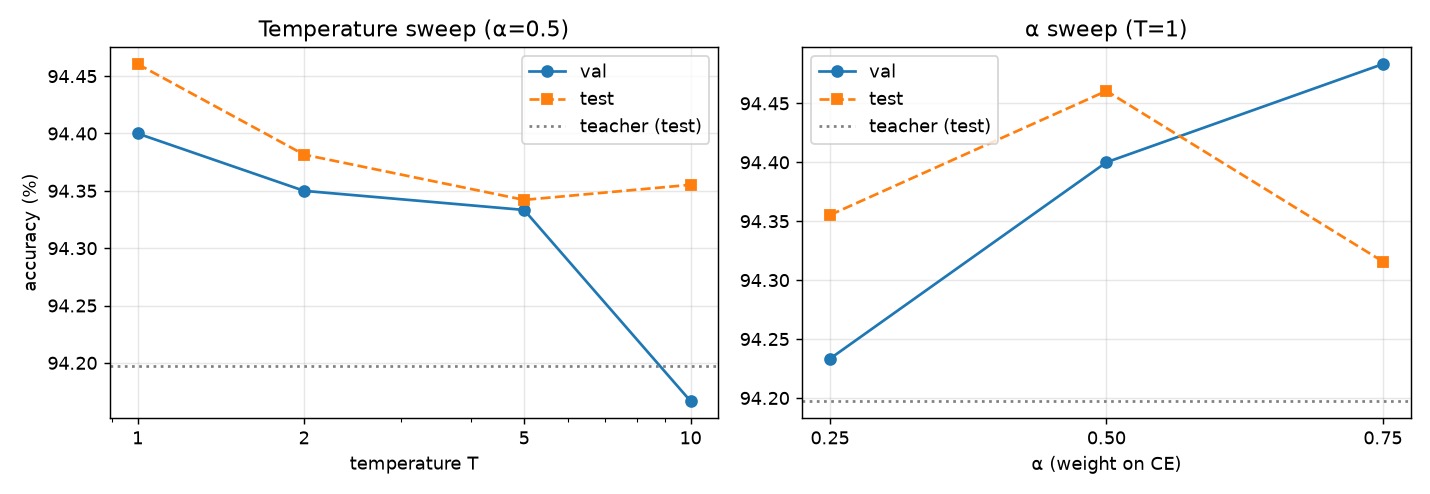

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for row, (runs, lab) in enumerate([(t_runs, lambda r: f"T={r['T']}"), (a_runs, lambda r: f"α={r['alpha']}")]):
    for col, key in enumerate(["loss", "ce", "kl"]):
        ax = axes[row, col]
        for r in runs:
            h = pd.DataFrame(r["history"]); ax.plot(h["step"], h[key], marker="o", ms=3, label=lab(r))
        ax.set_title({"loss": "total loss", "ce": "CE vs true labels", "kl": "KL·T² vs teacher"}[key] +
                     (" — temperature sweep (α=0.5)" if row == 0 else f" — α sweep (T={BEST_T})"), fontsize=10)
        ax.set_xlabel("training step"); ax.grid(alpha=.3); ax.legend(fontsize=8)
        if key == "kl": ax.set_yscale("log")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "p2_loss_trends.png"), dpi=130); plt.close()
display(Image(os.path.join(FIG, "p2_loss_trends.png")))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(t_df["T"], t_df["val_acc"]*100, "o-", label="val"); ax[0].plot(t_df["T"], t_df["test_acc"]*100, "s--", label="test")
ax[0].set_xscale("log"); ax[0].set_xticks(TEMPS); ax[0].set_xticklabels(TEMPS); ax[0].set_xlabel("temperature T"); ax[0].set_ylabel("accuracy (%)"); ax[0].set_title("Temperature sweep (α=0.5)")
ax[1].plot(a_df["alpha"], a_df["val_acc"]*100, "o-", label="val"); ax[1].plot(a_df["alpha"], a_df["test_acc"]*100, "s--", label="test")
ax[1].set_xticks(ALPHAS); ax[1].set_xlabel("α (weight on CE)"); ax[1].set_title(f"α sweep (T={BEST_T})")
for a in ax: a.axhline((TEACHER_TEST_PRED == test_y).mean()*100, color="gray", ls=":", label="teacher (test)"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG, "p2_sweeps.png"), dpi=130); plt.close()
display(Image(os.path.join(FIG, "p2_sweeps.png")))

## 7. Teacher vs. best distilled student — same AG News test set, same GPU
* **Accuracy**: full test set (7,600).
* **Latency**: one request = one tokenised news item at batch size 1, model forward only (tokenisation excluded), fp32,
  `torch.cuda.synchronize()` around each call; 20 warm-up requests, then 500 timed requests on the same fixed random test sample.
* **Throughput**: total time to classify the whole test set at batch 128 (fp32).
* **Peak GPU memory**: `torch.cuda.max_memory_allocated()` from model load through the full test-set pass and the latency run.
* **Size on disk**: `save_pretrained` folder (safetensors fp32 + config + tokenizer files).

In [10]:
def dir_mb(d): return sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(d) for f in fs) / 2**20
def weights_mb(d): return sum(os.path.getsize(os.path.join(d, f)) for f in os.listdir(d) if f.endswith((".safetensors", ".bin"))) / 2**20

rng = np.random.default_rng(SEED)
LAT_IDX = rng.choice(len(test_ids), size=min(500, len(test_ids)), replace=False)

def benchmark(path, name):
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    base_alloc = torch.cuda.memory_allocated()          # anything already resident (e.g. cached teacher logits) is excluded
    m = AutoModelForSequenceClassification.from_pretrained(path).to(device).eval()
    params = sum(p.numel() for p in m.parameters())
    t0 = time.time(); logits = predict_logits(m, test_ids, bs=128, amp=False); torch.cuda.synchronize(); full_s = time.time() - t0
    lat = []
    with torch.no_grad():
        for j, i in enumerate(np.concatenate([LAT_IDX[:20], LAT_IDX])):
            ids = torch.tensor([test_ids[i]], device=device); att = torch.ones_like(ids)
            torch.cuda.synchronize(); s = time.perf_counter()
            m(input_ids=ids, attention_mask=att); torch.cuda.synchronize()
            if j >= 20: lat.append((time.perf_counter() - s) * 1000)
    peak = (torch.cuda.max_memory_allocated() - base_alloc) / 2**30
    r = dict(model=name, params_M=params/1e6, accuracy=float((logits.argmax(1) == test_y).mean()),
             p50_ms=float(np.percentile(lat, 50)), p95_ms=float(np.percentile(lat, 95)), mean_ms=float(np.mean(lat)),
             testset_time_s=full_s, throughput_samples_s=len(test_ids)/full_s, peak_mem_GB=peak,
             disk_MB=dir_mb(path), weights_MB=weights_mb(path))
    del m; torch.cuda.empty_cache()
    return r, logits

best_dir = os.path.join(CKPT, BEST_TAG)
STUDENT_DIR = os.path.join(ROOT, "student_model_best" + SUF)
if os.path.abspath(best_dir) != STUDENT_DIR:
    shutil.rmtree(STUDENT_DIR, ignore_errors=True); shutil.copytree(best_dir, STUDENT_DIR)
bench_t, logits_t = benchmark(TEACHER_DIR, "Teacher (BERT-base)")
bench_s, logits_s = benchmark(STUDENT_DIR, f"Best distilled student (DistilBERT, T={best_run['T']}, α={BEST_ALPHA})")
bench = pd.DataFrame([bench_t, bench_s]); bench.to_csv(os.path.join(RES, "teacher_vs_student_benchmark.csv"), index=False)
log("Benchmark:\n" + bench.to_string(index=False))

tbl = pd.DataFrame({
    "Configuration": ["Teacher (BERT-base)", "Best distilled student"],
    "Accuracy": [f"{b['accuracy']*100:.2f} %" for b in (bench_t, bench_s)],
    "p50 / p95 latency (ms)": [f"{b['p50_ms']:.2f} / {b['p95_ms']:.2f}" for b in (bench_t, bench_s)],
    "Peak memory (GB)": [f"{b['peak_mem_GB']:.3f}" for b in (bench_t, bench_s)],
    "Size on disk (MB)": [f"{b['disk_MB']:.1f}" for b in (bench_t, bench_s)]})
print("Table HW11.2 — the separate distillation comparison on AG News"); display(tbl)
print(f"Student/teacher: params {bench_s['params_M']/bench_t['params_M']:.2f}x | disk {bench_s['disk_MB']/bench_t['disk_MB']:.2f}x | "
      f"p50 latency {bench_s['p50_ms']/bench_t['p50_ms']:.2f}x | test-set time {bench_s['testset_time_s']/bench_t['testset_time_s']:.2f}x | "
      f"accuracy retained {bench_s['accuracy']/bench_t['accuracy']*100:.2f} %")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  30%|██▉       | 60/201 [00:00<00:00, 584.06it/s]

Loading weights:  62%|██████▏   | 125/201 [00:00<00:00, 619.92it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 860.08it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:  97%|█████████▋| 101/104 [00:00<00:00, 1009.62it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1023.02it/s]

[2026-11-24 12:04:10] Benchmark:
                                           model   params_M  accuracy    p50_ms    p95_ms   mean_ms  testset_time_s  throughput_samples_s  peak_mem_GB    disk_MB  weights_MB
                             Teacher (BERT-base) 109.485316  0.941974 13.874427 21.851794 15.048850       39.097155            194.387545     0.929452 418.355692  417.675758
Best distilled student (DistilBERT, T=1, α=0.75)  66.956548  0.943158  7.818095 11.729042  8.257098       19.477819            390.187428     0.771017 256.110523  255.430908


Table HW11.2 — the separate distillation comparison on AG News


,Configuration,Accuracy,p50 / p95 latency (ms),Peak memory (GB),Size on disk (MB)
0,Teacher (BERT-base),94.20 %,13.87 / 21.85,0.929,418.4
1,Best distilled student,94.32 %,7.82 / 11.73,0.771,256.1


Student/teacher: params 0.61x | disk 0.61x | p50 latency 0.56x | test-set time 0.50x | accuracy retained 100.13 %


## 8. Where the compression hurts: per-class accuracy

,class,n,teacher_acc,student_acc,delta_pp
0,World,1900,0.9447,0.9426,-0.21
1,Sports,1900,0.9868,0.9900,+0.32
2,Business,1900,0.9021,0.9058,+0.37
3,Sci/Tech,1900,0.9342,0.9342,+0.00


[2026-11-24 12:04:10] Per-class accuracy:
   class    n  teacher_acc  student_acc  delta_pp
   World 1900     0.944737     0.942632 -0.210526
  Sports 1900     0.986842     0.990000  0.315789
Business 1900     0.902105     0.905789  0.368421
Sci/Tech 1900     0.934211     0.934211  0.000000
Class that degrades most: World


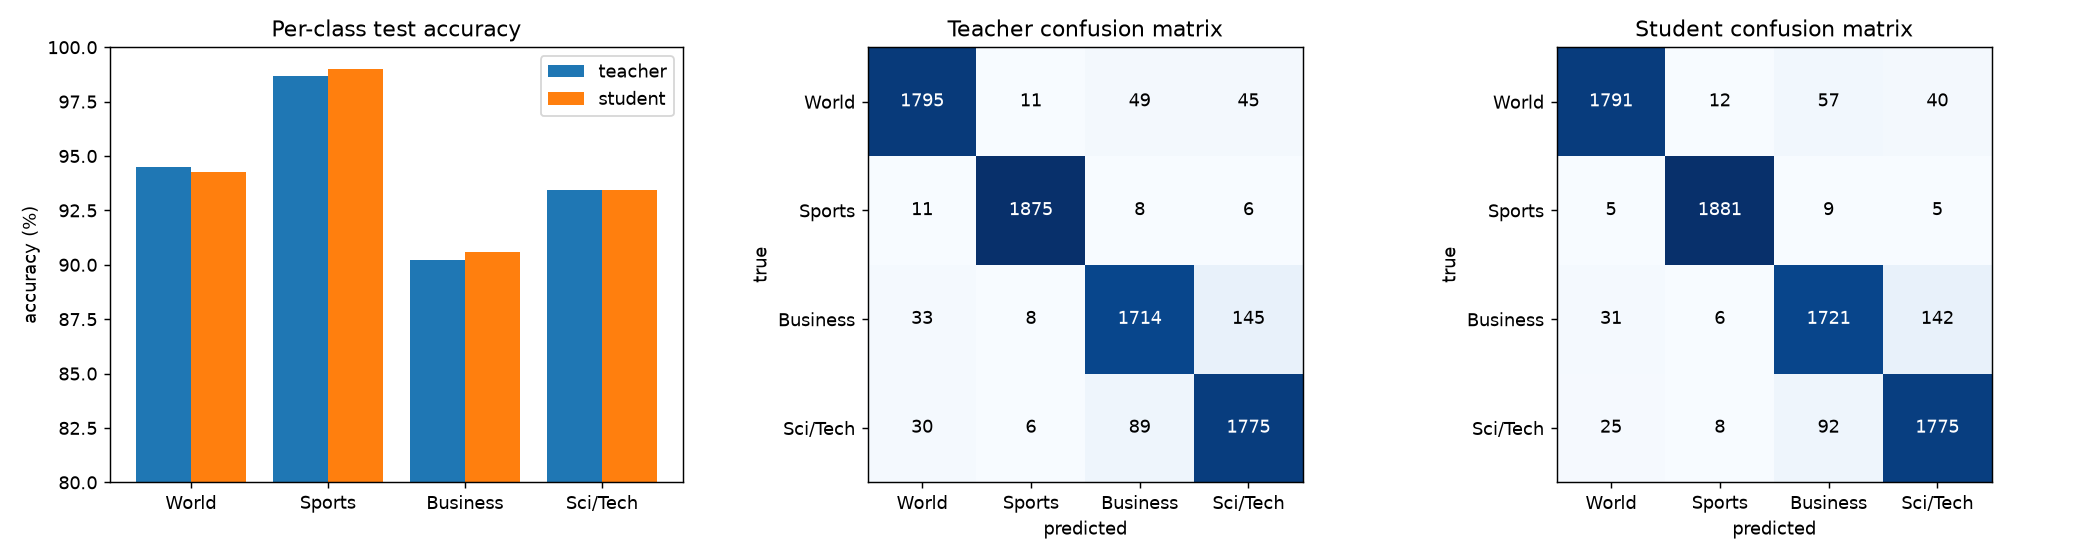

In [11]:
from sklearn.metrics import confusion_matrix
pt, ps = logits_t.argmax(1), logits_s.argmax(1)
pc = pd.DataFrame({"class": CLASSES,
                   "n": [int((test_y == c).sum()) for c in range(4)],
                   "teacher_acc": [(pt[test_y == c] == c).mean() for c in range(4)],
                   "student_acc": [(ps[test_y == c] == c).mean() for c in range(4)]})
pc["delta_pp"] = (pc["student_acc"] - pc["teacher_acc"]) * 100
pc.to_csv(os.path.join(RES, "per_class_accuracy.csv"), index=False)
display(pc.style.format({"teacher_acc": "{:.4f}", "student_acc": "{:.4f}", "delta_pp": "{:+.2f}"}))
WORST = int(pc["delta_pp"].idxmin())
log(f"Per-class accuracy:\n{pc.to_string(index=False)}\nClass that degrades most: {CLASSES[WORST]}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
x = np.arange(4); axes[0].bar(x-.2, pc["teacher_acc"]*100, .4, label="teacher"); axes[0].bar(x+.2, pc["student_acc"]*100, .4, label="student")
axes[0].set_xticks(x); axes[0].set_xticklabels(CLASSES); axes[0].set_ylim(80, 100); axes[0].set_ylabel("accuracy (%)"); axes[0].legend(); axes[0].set_title("Per-class test accuracy")
for ax, p, name in [(axes[1], pt, "Teacher"), (axes[2], ps, "Student")]:
    cm = confusion_matrix(test_y, p); ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    ax.set_xticks(x); ax.set_yticks(x); ax.set_xticklabels(CLASSES); ax.set_yticklabels(CLASSES); ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{name} confusion matrix")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "p2_per_class.png"), dpi=130); plt.close()
display(Image(os.path.join(FIG, "p2_per_class.png")))

In [12]:
pd.set_option("display.max_colwidth", None)
sm_t, sm_s = torch.softmax(torch.tensor(logits_t), -1).numpy(), torch.softmax(torch.tensor(logits_s), -1).numpy()
mask = (test_y == WORST) & (pt == WORST) & (ps != WORST)
cand = np.where(mask)[0]
print(f"{len(cand)} test items of class '{CLASSES[WORST]}' are right for the teacher and wrong for the student "
      f"(vs {int(((test_y == WORST) & (pt != WORST) & (ps == WORST)).sum())} the other way round).")
print("Where do the student's errors on these items go?", pd.Series(ps[cand]).map(dict(enumerate(CLASSES))).value_counts().to_dict())
# five examples: the ones the student gets most confidently wrong (deterministic choice)
pick = cand[np.argsort(-sm_s[cand].max(1))][:5]
ex = pd.DataFrame({"test_idx": pick, "text": [test_text[i] for i in pick],
                   "teacher_pred (p)": [f"{CLASSES[pt[i]]} ({sm_t[i, pt[i]]:.2f})" for i in pick],
                   "student_pred (p)": [f"{CLASSES[ps[i]]} ({sm_s[i, ps[i]]:.2f})" for i in pick],
                   "student p(true)": [round(float(sm_s[i, WORST]), 2) for i in pick],
                   "tokens": [len(test_ids[i]) for i in pick]})
ex.to_csv(os.path.join(RES, "worst_class_examples.csv"), index=False)
all_wrong = pd.DataFrame({"text": [test_text[i] for i in cand], "student_pred": [CLASSES[ps[i]] for i in cand]})
all_wrong.to_csv(os.path.join(RES, "worst_class_all_teacher_right_student_wrong.csv"), index=False)
display(ex)
for i in pick:
    print(f"\n[{i}] true={CLASSES[test_y[i]]} | teacher={CLASSES[pt[i]]} | student={CLASSES[ps[i]]}\n    {test_text[i]}")

19 test items of class 'World' are right for the teacher and wrong for the student (vs 15 the other way round).
Where do the student's errors on these items go? {'Business': 10, 'Sports': 5, 'Sci/Tech': 4}


,test_idx,text,teacher_pred (p),student_pred (p),student p(true),tokens
0,528,Update 1: Passengers Stranded by Canceled Flights Thousands of disgruntled vacationers were stranded at Heathrow Airport Tuesday after British Airways canceled scores of flights because of staff shortages and technical hitches.,World (0.58),Business (0.91),0.08,41
1,1617,"At Last, Success on the Road for Lions The Detroit Lions went three full seasons without winning an away game, setting an NFL record for road futility. They ended that ignominious streak Sunday in their first opportunity of the season, beating the Chicago Bears 20-16 at Soldier Field...",World (0.88),Sports (0.88),0.11,63
2,6698,"Terms of Endearment Seems that the Bush administration, unlike previous White Houses, is not necessarily averse to allowing its ambassadors to have second tours. For example, word is that John Thomas ""Tom "" Schieffer , the Texas oilman who brought President Bush into the Texas Rangers baseball club partnership and who is now ambassador to Australia, is to hang out in the Pacific a while longer, this time as ambassador to Japan.",World (0.78),Sports (0.85),0.12,89
3,2183,"Election chaos? (U.S. News World Report) U.S. News World Report - Michael Cadigan's day job is practicing commercial law in Albuquerque. But over eggs at the trendy Gold Street Caffe in the heart of downtown, he and a dozen other lawyers are immersing themselves in the intricacies of election law. On Election Day, they plan to be out in force for Democrat John Kerry at polling places across New Mexico, where Al Gore won in 2000 by just 366 votes. quot;We know there was a lot of monkey business with counting ballots before, quot; says Cadigan. quot;We want to make sure that doesn't happen again. ...",World (0.85),Sci/Tech (0.84),0.13,128
4,6150,England humble Sprinboks Charlie Hodgson scores 27 points as England overwhelm the Springboks at Twickenham.,World (0.98),Sports (0.76),0.23,27



[528] true=World | teacher=World | student=Business
    Update 1: Passengers Stranded by Canceled Flights Thousands of disgruntled vacationers were stranded at Heathrow Airport Tuesday after British Airways canceled scores of flights because of staff shortages and technical hitches.

[1617] true=World | teacher=World | student=Sports
    At Last, Success on the Road for Lions The Detroit Lions went three full seasons without winning an away game, setting an NFL record for road futility. They ended that ignominious streak Sunday in their first opportunity of the season, beating the Chicago Bears 20-16 at Soldier Field...

[6698] true=World | teacher=World | student=Sports
    Terms of Endearment   Seems that the Bush administration, unlike previous White Houses, is not necessarily averse to allowing its ambassadors to have second tours. For example, word is that    John     Thomas "Tom    " Schieffer , the Texas oilman who brought    President Bush  into the Texas Rangers baseball club

In [13]:
summary = dict(SID4=SID4, SEED=SEED, teacher_source=TEACHER_SOURCE, best_T=BEST_T, best_tag=BEST_TAG, best_alpha=BEST_ALPHA,
               temperature_sweep=t_df.to_dict("records"), alpha_sweep=a_df.to_dict("records"),
               benchmark=bench.to_dict("records"), per_class=pc.to_dict("records"), worst_class=CLASSES[WORST],
               worst_class_examples=ex.drop(columns=["text"]).assign(text=[test_text[i] for i in pick]).to_dict("records"),
               gpu=torch.cuda.get_device_name(0), torch=torch.__version__, transformers=transformers.__version__)
json.dump(summary, open(os.path.join(RES, "summary.json"), "w"), indent=1, default=float)
log("===== Part 2 run finished =====")

[2026-11-24 12:04:14] ===== Part 2 run finished =====


## 9. Findings — Knowledge distillation (teacher vs. student, same AG News test set, same RTX 3060 Laptop GPU)

**Teacher note.** The instructor's `teacher_model` Drive folder was access-restricted (HTTP 401), so the teacher here is a
stand-in: `bert-base-uncased` fine-tuned for 1 epoch on the 114k fit split. It scores 94.42 % on validation and **94.20 % on test**.
Logits were extracted for all 120,000 training samples (177 s).

### Distillation temperature sweep (α = 0.5, fresh student per run, SEED = 2122, all other settings fixed)

| T | val acc | test acc | test agreement with teacher |
|---|---|---|---|
| **1** | **94.40 %** | **94.46 %** | 98.33 % |
| 2 | 94.35 % | 94.38 % | 98.28 % |
| 5 | 94.33 % | 94.34 % | 98.25 % |
| 10 | 94.17 % | 94.36 % | 98.39 % |

**Best temperature: T = 1** (selected on validation accuracy). The spread is small: 0.23 pp on validation, where one standard
error at n = 6,000 is about 0.30 pp. The trend still makes sense:
* The teacher's training-set logits are very confident (mean max-probability 0.956 at T = 1) because it was trained on those samples.
* Raising T flattens them toward uniform: max-probability 0.38 and entropy 1.34 nats at T = 10, against a 4-class maximum of 1.39.
* With only 4 classes there is little "dark knowledge" (relative similarity between wrong classes) to transfer. High temperatures mostly
  dilute the signal, and the student cannot match the flattened targets in one epoch: KL·T² stays about 3× higher at T = 5 or 10 than at T = 1
  (see the loss-trend plot).

### Loss-weighting sweep (T = 1, three fresh students)

| α (weight on CE) | val acc | test acc | test agreement with teacher |
|---|---|---|---|
| 0.25 | 94.23 % | 94.36 % | 98.39 % |
| 0.50 | 94.40 % | **94.46 %** | 98.33 % |
| **0.75** | **94.48 %** | 94.32 % | 97.86 % |

By the pre-declared rule (highest validation accuracy), the best student is **T = 1, α = 0.75**, and it is benchmarked below.
* α = 0.5 is best on test, and the validation and test rankings disagree. Within 0.25 pp, the three α values are statistically
  indistinguishable.
* The systematic effect is in *teacher agreement*: the more weight on the KD term (smaller α), the more closely the student copies
  the teacher (98.39 % → 97.86 %).
* The α = 0.5 run reproduced the T = 1 sweep run exactly, which confirms the runs are deterministic under the fixed seed.

**Loss trends:** CE falls from about 0.43 to 0.17 within one epoch in every run. The KL term falls by more than an order of magnitude.
The total loss is lowest for small α only because the KL term is numerically smaller than CE; total loss is not comparable across α.

### Table HW11.2 — the separate distillation comparison on AG News

| Configuration | Accuracy | p50 / p95 latency (ms)¹ | Peak memory (GB)² | Size on disk (MB) |
|---|---|---|---|---|
| Teacher (BERT-base, 109.5M params) | 94.20 % | 13.87 / 21.85 | 0.929 | 418.4 |
| Best distilled student (DistilBERT, 67.0M params, T = 1, α = 0.75) | 94.32 % | 7.82 / 11.73 | 0.771 | 256.1 |

¹ Batch 1, one news item per request, fp32, model forward only, 500 timed requests. Whole test set at batch 128:
39.1 s (194 items/s) for the teacher vs 19.5 s (390 items/s) for the student.
² Peak allocated during the full test-set pass and the latency run, excluding memory resident before the model was loaded.

The student has **0.61×** the parameters and on-disk size, **1.77×** lower p50 latency, **2.0×** the throughput and **0.83×** the peak
memory, and it **keeps 100 % of the teacher's accuracy** (94.32 % vs 94.20 %; the +0.12 pp is within noise). On this task,
distillation into DistilBERT is effectively free.

### Where the compression hurts — per-class accuracy

| Class | Teacher | Student | Δ (pp) |
|---|---|---|---|
| World | 94.47 % | 94.26 % | **−0.21** |
| Sports | 98.68 % | 99.00 % | +0.32 |
| Business | 90.21 % | 90.58 % | +0.37 |
| Sci/Tech | 93.42 % | 93.42 % | 0.00 |

**World** is the only class that degrades, and only slightly: 19 World items are right for the teacher and wrong for the student, and 15 the
other way round. The student sends 10 of those 19 to Business, 5 to Sports and 4 to Sci/Tech. The five examples in §8 have
one thing in common: they are **World-labelled stories whose dominant vocabulary belongs to another class**:
* British Airways cancelling flights at Heathrow → *Business*
* the Detroit Lions winning an NFL road game → *Sports*
* an ambassador posting described through the Texas Rangers baseball club → *Sports*
* lawyers preparing for election-day ballot counting → *Sci/Tech*
* England beating the Springboks at rugby → *Sports*

The World label reflects the outlet or framing (international or political news) rather than the surface topic. Several of these items
(an NFL game and a rugby match labelled World) look like AG News label noise. The larger teacher partly fits such source-specific quirks,
while the 6-layer student relies more on topical keywords and follows the surface topic.

### Quantisation vs. distillation as compression approaches (uses Part 1 and Part 2 measurements; accuracies are not compared)
GPTQ needed no training: in 47 s on a small WikiText-2 calibration set it halved OPT-125m's on-disk size (242 → 123 MB) and
resident weights (0.23 → 0.12 GB), at a cost of +4.5 perplexity. On this GPU at batch 1 it made generation about 2× *slower*
(p50 2.10 s → 4.14 s per 128 tokens) and lowered peak memory only 9 %, because a 125M-parameter model is bound by kernel launches
and activations rather than by weight bandwidth. Distillation cost a teacher logit pass plus about 5.5 min of training per student. It
produced an architecturally smaller network (6 vs 12 layers, 67M vs 110M parameters) that cut p50 latency 1.77×, doubled throughput,
and shrank disk size 0.61× and peak memory 0.83× while keeping the teacher's quality on its task. The mechanisms differ:
quantisation reduces *bytes per weight* but keeps the same compute graph and adds dequantisation work, while distillation removes
*layers*, and therefore FLOPs and kernel launches. **For a latency-bound deployment I would try distillation first; for a
memory-bound deployment (fitting a large LLM into limited VRAM or disk) I would try GPTQ first.** The two can also be stacked by
quantising a distilled student.